In [ ]:
!pip install -q datasets pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
dataset = load_dataset(
    "Dingdong-Inc/FreshRetailNet-50K",
    split="train",
    streaming=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Dataset Columns:")

for column in dataset.features:
    print(column)


Dataset Columns:
city_id
store_id
management_group_id
first_category_id
second_category_id
third_category_id
product_id
dt
sale_amount
hours_sale
stock_hour6_22_cnt
hours_stock_status
discount
holiday_flag
activity_flag
precpt
avg_temperature
avg_humidity
avg_wind_level


In [ ]:
print(dataset.features)

{'city_id': Value('int64'), 'store_id': Value('int64'), 'management_group_id': Value('int64'), 'first_category_id': Value('int64'), 'second_category_id': Value('int64'), 'third_category_id': Value('int64'), 'product_id': Value('int64'), 'dt': Value('string'), 'sale_amount': Value('float64'), 'hours_sale': List(Value('float64')), 'stock_hour6_22_cnt': Value('int32'), 'hours_stock_status': List(Value('int64')), 'discount': Value('float64'), 'holiday_flag': Value('int32'), 'activity_flag': Value('int32'), 'precpt': Value('float64'), 'avg_temperature': Value('float64'), 'avg_humidity': Value('float64'), 'avg_wind_level': Value('float64')}


In [ ]:
first_5 = list(dataset.take(5))

df = pd.DataFrame(first_5)

pd.set_option("display.max_columns", None)

display(df)

,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25


In [ ]:
sample_df = pd.DataFrame(list(dataset.take(1000)))

print("Sample Rows:", sample_df.shape[0])
print("Sample Columns:", sample_df.shape[1])

Sample Rows: 1000
Sample Columns: 19


In [ ]:
sample_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   city_id              1000 non-null   int64  
 1   store_id             1000 non-null   int64  
 2   management_group_id  1000 non-null   int64  
 3   first_category_id    1000 non-null   int64  
 4   second_category_id   1000 non-null   int64  
 5   third_category_id    1000 non-null   int64  
 6   product_id           1000 non-null   int64  
 7   dt                   1000 non-null   object 
 8   sale_amount          1000 non-null   float64
 9   hours_sale           1000 non-null   object 
 10  stock_hour6_22_cnt   1000 non-null   int64  
 11  hours_stock_status   1000 non-null   object 
 12  discount             1000 non-null   float64
 13  holiday_flag         1000 non-null   int64  
 14  activity_flag        1000 non-null   int64  
 15  precpt               1000 non-null   fl

In [ ]:
missing_values = sample_df.isnull().sum()

print(missing_values)

city_id                0
store_id               0
management_group_id    0
first_category_id      0
second_category_id     0
third_category_id      0
product_id             0
dt                     0
sale_amount            0
hours_sale             0
stock_hour6_22_cnt     0
hours_stock_status     0
discount               0
holiday_flag           0
activity_flag          0
precpt                 0
avg_temperature        0
avg_humidity           0
avg_wind_level         0
dtype: int64


In [ ]:
hashable_df = sample_df.map(
    lambda x: tuple(x) if isinstance(x, list) else x
)

duplicates = hashable_df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


In [ ]:
sample_df.describe()

,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,sale_amount,stock_hour6_22_cnt,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
count,1000.0,1000.0,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.0,0.0,1.47000,23.960000,64.160000,136.730000,506.510000,0.96071,4.380000,0.936181,0.346000,0.30600,3.134957,21.260330,74.178770,1.644660
std,0.0,0.0,0.89995,10.283197,24.068521,68.627595,260.072081,1.15189,4.793598,0.084460,0.475931,0.46106,2.969060,3.551352,5.178804,0.230067
min,0.0,0.0,0.00000,0.000000,6.000000,60.000000,4.000000,0.00000,0.000000,0.500000,0.000000,0.00000,0.293100,15.080000,63.290000,1.080000
25%,0.0,0.0,0.00000,28.000000,72.000000,60.000000,379.000000,0.30000,0.000000,0.882000,0.000000,0.00000,1.328900,18.030000,70.260000,1.480000
50%,0.0,0.0,2.00000,29.000000,76.000000,154.000000,596.000000,0.60000,4.000000,0.979500,0.000000,0.00000,2.072850,21.240000,74.450000,1.650000
75%,0.0,0.0,2.00000,29.000000,76.000000,218.000000,699.000000,1.20000,7.000000,1.000000,1.000000,1.00000,3.202500,23.570000,77.430000,1.770000
max,0.0,0.0,3.00000,30.000000,78.000000,231.000000,834.000000,12.00000,16.000000,1.000000,1.000000,1.00000,14.206300,28.010000,86.840000,2.250000


In [ ]:
columns = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id"
]

for col in columns:
    print(col, ":", sample_df[col].nunique())

city_id : 1
store_id : 1
management_group_id : 3
first_category_id : 6
second_category_id : 7
third_category_id : 10
product_id : 12


In [ ]:
sample_df["dt"] = pd.to_datetime(sample_df["dt"])

print("Start Date:", sample_df["dt"].min())
print("End Date:", sample_df["dt"].max())
print("Unique Dates:", sample_df["dt"].nunique())

Start Date: 2024-03-28 00:00:00
End Date: 2024-06-25 00:00:00
Unique Dates: 90


In [ ]:
print("Sales Mean:", sample_df["sale_amount"].mean())
print("Sales Median:", sample_df["sale_amount"].median())
print("Minimum Sales:", sample_df["sale_amount"].min())
print("Maximum Sales:", sample_df["sale_amount"].max())
print("Sales Standard Deviation:", sample_df["sale_amount"].std())

Sales Mean: 0.9607100000000001
Sales Median: 0.6
Minimum Sales: 0.0
Maximum Sales: 12.0
Sales Standard Deviation: 1.1518895978111563


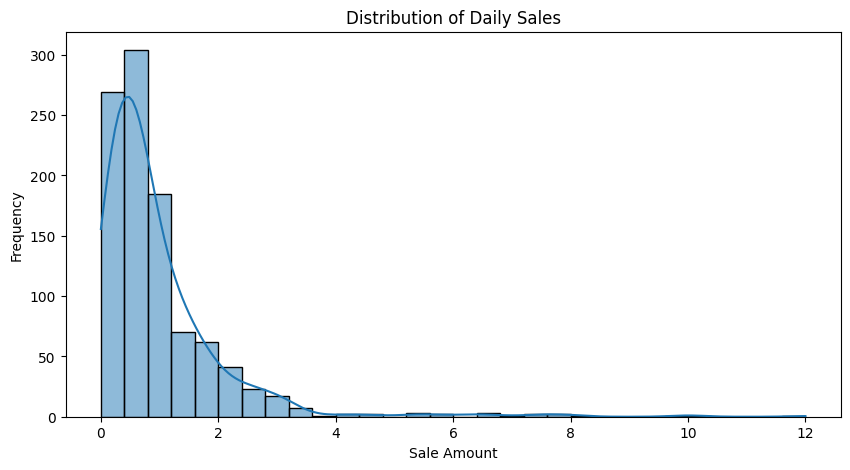

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=sample_df,
    x="sale_amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Sales")
plt.xlabel("Sale Amount")
plt.ylabel("Frequency")

plt.show()

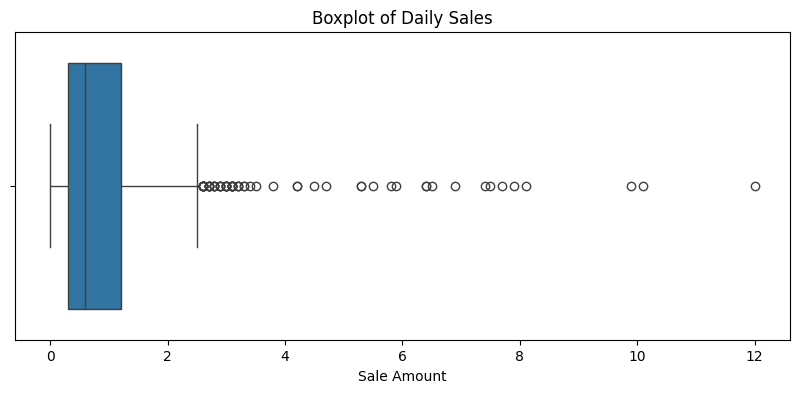

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=sample_df,
    x="sale_amount"
)

plt.title("Boxplot of Daily Sales")
plt.xlabel("Sale Amount")

plt.show()

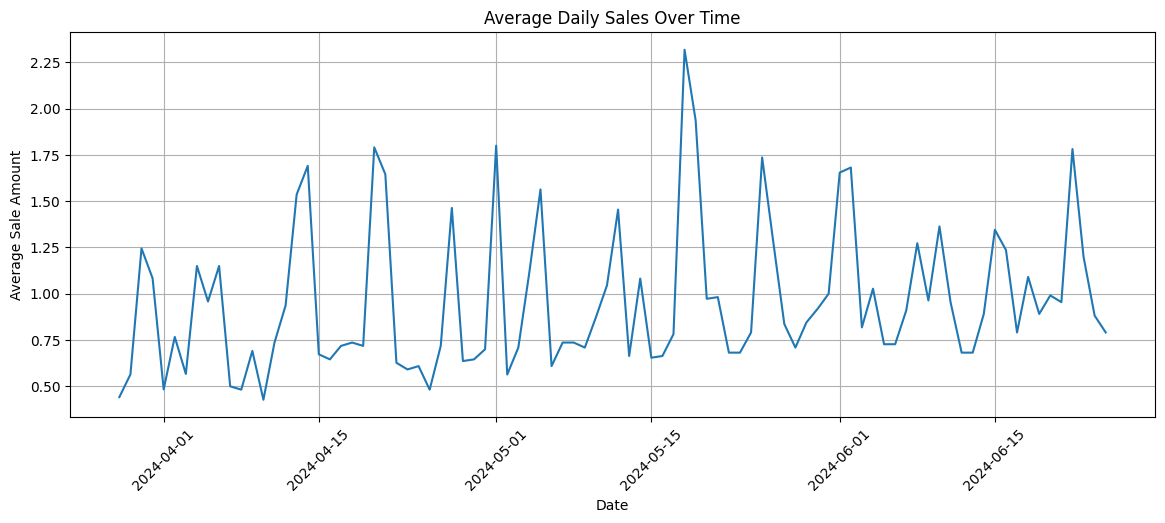

In [ ]:
daily_sales = sample_df.groupby("dt")["sale_amount"].mean()

plt.figure(figsize=(14, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Average Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Average Sale Amount")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [ ]:
zero_sales = (sample_df["sale_amount"] == 0).sum()
non_zero_sales = (sample_df["sale_amount"] > 0).sum()

print("Zero Sales Records:", zero_sales)
print("Non-Zero Sales Records:", non_zero_sales)

print(
    "Zero Sales Percentage:",
    round((zero_sales / len(sample_df)) * 100, 2),
    "%"
)

Zero Sales Records: 61
Non-Zero Sales Records: 939
Zero Sales Percentage: 6.1 %


In [ ]:
print("hours_sale lengths:")

print(
    sample_df["hours_sale"].apply(len).value_counts()
)

print("\nhours_stock_status lengths:")

print(
    sample_df["hours_stock_status"].apply(len).value_counts()
)

hours_sale lengths:
hours_sale
24    1000
Name: count, dtype: int64

hours_stock_status lengths:
hours_stock_status
24    1000
Name: count, dtype: int64


In [ ]:
stock_values = [
    value
    for row in sample_df["hours_stock_status"]
    for value in row
]

print("Unique Stock Status Values:")

print(sorted(set(stock_values)))

Unique Stock Status Values:
[0, 1]


0    16111
1     7889
Name: count, dtype: int64


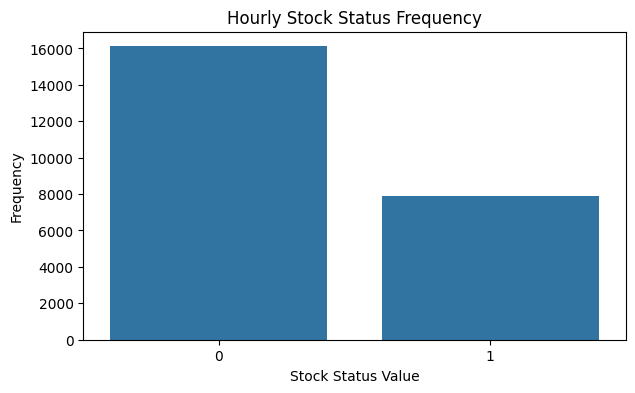

In [ ]:
stock_counts = pd.Series(stock_values).value_counts().sort_index()

print(stock_counts)

plt.figure(figsize=(7, 4))

sns.barplot(
    x=stock_counts.index.astype(str),
    y=stock_counts.values
)

plt.title("Hourly Stock Status Frequency")
plt.xlabel("Stock Status Value")
plt.ylabel("Frequency")

plt.show()

count    1000.000000
mean        4.380000
std         4.793598
min         0.000000
25%         0.000000
50%         4.000000
75%         7.000000
max        16.000000
Name: stock_hour6_22_cnt, dtype: float64


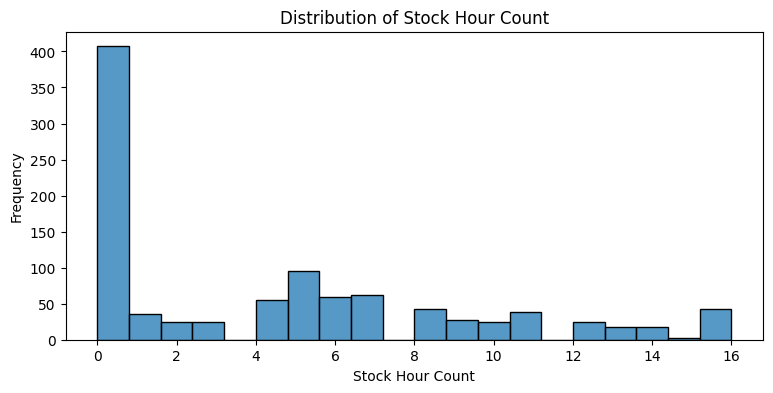

In [ ]:
print(sample_df["stock_hour6_22_cnt"].describe())

plt.figure(figsize=(9, 4))

sns.histplot(
    data=sample_df,
    x="stock_hour6_22_cnt",
    bins=20
)

plt.title("Distribution of Stock Hour Count")
plt.xlabel("Stock Hour Count")
plt.ylabel("Frequency")

plt.show()

In [ ]:
stock_counts = pd.Series(stock_values).value_counts().sort_index()

print("Stock Status Counts:")
print(stock_counts)

print("\nStock Status Percentages:")
print(stock_counts / len(stock_values) * 100)

Stock Status Counts:
0    16111
1     7889
Name: count, dtype: int64

Stock Status Percentages:
0    67.129167
1    32.870833
Name: count, dtype: float64


In [ ]:
print(sample_df["stock_hour6_22_cnt"].describe())

print("\nUnique Values:")
print(sorted(sample_df["stock_hour6_22_cnt"].unique()))

count    1000.000000
mean        4.380000
std         4.793598
min         0.000000
25%         0.000000
50%         4.000000
75%         7.000000
max        16.000000
Name: stock_hour6_22_cnt, dtype: float64

Unique Values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]


In [ ]:
# Calculate out-of-stock hours between 6 AM and 10 PM
calculated_stock_count = sample_df["hours_stock_status"].apply(
    lambda row: sum(row[6:22])
)

# Compare with existing column
comparison = pd.DataFrame({
    "Actual_Count": sample_df["stock_hour6_22_cnt"],
    "Calculated_Count": calculated_stock_count
})

comparison["Match"] = (
    comparison["Actual_Count"] == comparison["Calculated_Count"]
)

display(comparison.head(10))

print("\nTotal Matching Rows:", comparison["Match"].sum())
print("Total Mismatching Rows:", (~comparison["Match"]).sum())

,Actual_Count,Calculated_Count,Match
0,0,0,True
1,1,1,True
2,0,0,True
3,11,11,True
4,8,8,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True



Total Matching Rows: 1000
Total Mismatching Rows: 0


In [ ]:
sample_df["daily_stockout"] = (
    sample_df["stock_hour6_22_cnt"] > 0
).astype(int)

print(sample_df["daily_stockout"].value_counts())

print("\n0 = No stockout")
print("1 = Stockout occurred")

daily_stockout
1    593
0    407
Name: count, dtype: int64

0 = No stockout
1 = Stockout occurred


In [ ]:
stockout_analysis = sample_df.groupby("daily_stockout")["sale_amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(stockout_analysis)

,count,mean,median,min,max
daily_stockout,,,,,
0,407,0.954472,0.6,0.0,10.1
1,593,0.964992,0.6,0.0,12.0


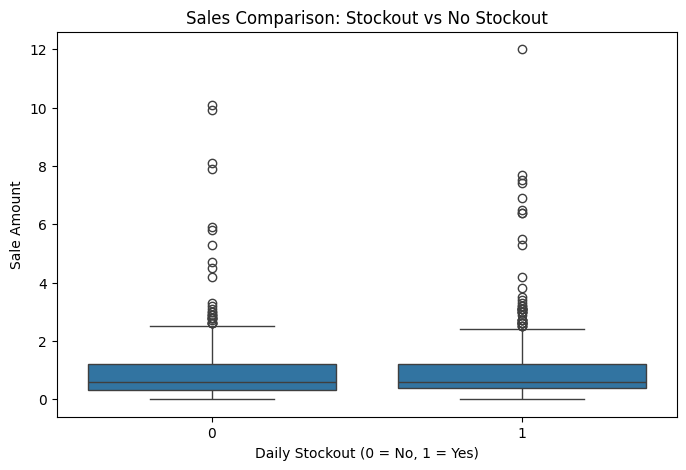

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=sample_df,
    x="daily_stockout",
    y="sale_amount"
)

plt.title("Sales Comparison: Stockout vs No Stockout")
plt.xlabel("Daily Stockout (0 = No, 1 = Yes)")
plt.ylabel("Sale Amount")

plt.show()

In [ ]:
product_sales = (
    sample_df.groupby("product_id")["sale_amount"]
    .agg(["count", "mean", "sum"])
    .sort_values("sum", ascending=False)
)

display(product_sales)

,count,mean,sum
product_id,,,
4,90,2.701111,243.10
580,90,1.801111,162.10
834,90,1.294444,116.50
596,90,1.168889,105.20
740,90,0.703333,63.30
600,90,0.677778,61.00
699,90,0.608889,54.80
38,90,0.436667,39.30
379,90,0.436667,39.30


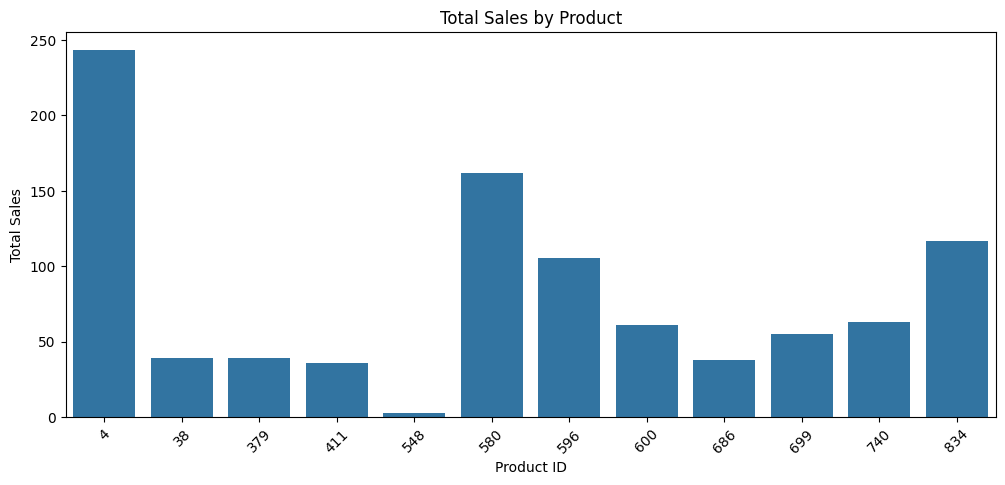

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=product_sales.reset_index(),
    x="product_id",
    y="sum"
)

plt.title("Total Sales by Product")
plt.xlabel("Product ID")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()

In [ ]:
print(stockout_analysis.to_string())

                count      mean  median  min   max
daily_stockout                                    
0                 407  0.954472     0.6  0.0  10.1
1                 593  0.964992     0.6  0.0  12.0


In [ ]:
print(product_sales.to_string())

            count      mean     sum
product_id                         
4              90  2.701111  243.10
580            90  1.801111  162.10
834            90  1.294444  116.50
596            90  1.168889  105.20
740            90  0.703333   63.30
600            90  0.677778   61.00
699            90  0.608889   54.80
38             90  0.436667   39.30
379            90  0.436667   39.30
686            90  0.420000   37.80
411            90  0.396667   35.70
548            10  0.261000    2.61


In [ ]:
print(sample_df["discount"].describe())

print("\nUnique Discount Values:")
print(sample_df["discount"].nunique())

count    1000.000000
mean        0.936181
std         0.084460
min         0.500000
25%         0.882000
50%         0.979500
75%         1.000000
max         1.000000
Name: discount, dtype: float64

Unique Discount Values:
171


In [ ]:
discount_analysis = sample_df.groupby("discount")["sale_amount"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

print(discount_analysis.to_string())

          count      mean  median
discount                         
0.790000      1  7.700000    7.70
0.798000      1  7.400000    7.40
0.844000      1  6.900000    6.90
0.855000      2  6.800000    6.80
0.795000      1  6.400000    6.40
0.778000      1  5.800000    5.80
0.860000      2  5.400000    5.40
0.879000      2  4.450000    4.45
0.812000      2  4.200000    4.20
0.876000      4  3.875000    4.20
0.852000      2  3.800000    3.80
0.919000      1  3.400000    3.40
0.526000      1  3.300000    3.30
0.776000      1  3.100000    3.10
0.755000      1  3.100000    3.10
0.545000      1  3.000000    3.00
0.853000      7  2.785714    1.40
0.847000      3  2.733333    1.10
0.887000      2  2.700000    2.70
0.833000      2  2.700000    2.70
0.881000      4  2.650000    1.00
0.500000      8  2.625000    2.60
0.899000      1  2.600000    2.60
0.949000      1  2.600000    2.60
0.977000      1  2.600000    2.60
0.955000      1  2.400000    2.40
0.989000      3  2.300000    2.10
0.997000      

In [ ]:
correlation = sample_df["discount"].corr(
    sample_df["sale_amount"]
)

print("Discount-Sales Correlation:", correlation)

Discount-Sales Correlation: -0.25999381220187234


In [ ]:
weather_correlation = sample_df[
    [
        "sale_amount",
        "precpt",
        "avg_temperature",
        "avg_humidity",
        "avg_wind_level"
    ]
].corr()

print(weather_correlation.round(3))

                 sale_amount  precpt  avg_temperature  avg_humidity  \
sale_amount            1.000   0.014            0.077         0.006   
precpt                 0.014   1.000            0.555         0.723   
avg_temperature        0.077   0.555            1.000         0.084   
avg_humidity           0.006   0.723            0.084         1.000   
avg_wind_level        -0.023  -0.102            0.006        -0.200   

                 avg_wind_level  
sale_amount              -0.023  
precpt                   -0.102  
avg_temperature           0.006  
avg_humidity             -0.200  
avg_wind_level            1.000  


In [ ]:
import psutil

ram = psutil.virtual_memory()

print("Total RAM:", round(ram.total / (1024**3), 2), "GB")
print("Available RAM:", round(ram.available / (1024**3), 2), "GB")

Total RAM: 12.67 GB
Available RAM: 6.4 GB


In [ ]:
from itertools import islice

records = list(islice(dataset, 100000))

full_sample_df = pd.DataFrame(records)

print("Rows:", full_sample_df.shape[0])
print("Columns:", full_sample_df.shape[1])

print("\nUnique Stores:", full_sample_df["store_id"].nunique())
print("Unique Products:", full_sample_df["product_id"].nunique())
print("Unique Cities:", full_sample_df["city_id"].nunique())

Rows: 100000
Columns: 19

Unique Stores: 13
Unique Products: 273
Unique Cities: 1


In [ ]:
full_sample_df["dt"] = pd.to_datetime(full_sample_df["dt"])

print("Start Date:", full_sample_df["dt"].min())
print("End Date:", full_sample_df["dt"].max())
print("Unique Dates:", full_sample_df["dt"].nunique())

Start Date: 2024-03-28 00:00:00
End Date: 2024-06-25 00:00:00
Unique Dates: 90


In [ ]:
print(
    full_sample_df["store_id"]
    .value_counts()
    .sort_index()
    .to_string()
)

store_id
0      6660
1     11880
2      7650
8      6300
12     4860
18    14760
19     6660
24     6570
29     9990
34     8820
35     6210
41     6210
46     3430


In [ ]:
series_summary = (
    full_sample_df
    .groupby(["store_id", "product_id"])
    .agg(
        records=("dt", "count"),
        unique_dates=("dt", "nunique"),
        total_sales=("sale_amount", "sum")
    )
    .reset_index()
)

print("Total Store-Product Series:", len(series_summary))

print("\nRecords per Series:")
print(series_summary["records"].describe())

print("\nSeries with 90 Dates:",
      (series_summary["unique_dates"] == 90).sum())

print("Series with Less Than 90 Dates:",
      (series_summary["unique_dates"] < 90).sum())

Total Store-Product Series: 1112

Records per Series:
count    1112.000000
mean       89.928058
std         2.399041
min        10.000000
25%        90.000000
50%        90.000000
75%        90.000000
max        90.000000
Name: records, dtype: float64

Series with 90 Dates: 1111
Series with Less Than 90 Dates: 1


In [ ]:
incomplete_series = series_summary[
    series_summary["unique_dates"] < 90
]

print(incomplete_series.to_string(index=False))

 store_id  product_id  records  unique_dates  total_sales
       46         249       10            10          9.2


In [ ]:
# Step 47: Sort data chronologically

model_df = full_sample_df.sort_values(
    ["store_id", "product_id", "dt"]
).copy()

# Incomplete series remove
model_df = model_df[
    model_df.groupby(
        ["store_id", "product_id"]
    )["dt"].transform("count") == 90
].copy()

# Previous sales features
grouped_sales = model_df.groupby(
    ["store_id", "product_id"]
)["sale_amount"]

model_df["lag_1"] = grouped_sales.shift(1)
model_df["lag_7"] = grouped_sales.shift(7)
model_df["lag_14"] = grouped_sales.shift(14)

model_df["rolling_mean_7"] = (
    model_df.groupby(
        ["store_id", "product_id"]
    )["sale_amount"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

# Next day's sales as target
model_df["next_day_sale"] = (
    model_df.groupby(
        ["store_id", "product_id"]
    )["sale_amount"].shift(-1)
)

# Remove rows with missing features/target
model_df = model_df.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_14",
        "rolling_mean_7",
        "next_day_sale"
    ]
).copy()

print("Final Modeling Rows:", len(model_df))
print("Total Features:", 4)
print("\nSample:")
print(
    model_df[
        [
            "store_id",
            "product_id",
            "dt",
            "lag_1",
            "lag_7",
            "lag_14",
            "rolling_mean_7",
            "next_day_sale"
        ]
    ].head(10).to_string(index=False)
)

Final Modeling Rows: 83325
Total Features: 4

Sample:
 store_id  product_id         dt  lag_1  lag_7  lag_14  rolling_mean_7  next_day_sale
        0           4 2024-04-11    0.7    4.7     0.5        2.771429            3.1
        0           4 2024-04-12    1.6    3.1     1.3        2.328571            6.4
        0           4 2024-04-13    3.1    5.5     5.3        2.328571            7.7
        0           4 2024-04-14    6.4    1.5     4.2        2.457143            1.5
        0           4 2024-04-15    7.7    1.9     0.7        3.342857            1.7
        0           4 2024-04-16    1.5    2.0     2.3        3.285714            1.2
        0           4 2024-04-17    1.7    0.7     1.3        3.242857            1.1
        0           4 2024-04-18    1.2    1.6     4.7        3.314286            1.4
        0           4 2024-04-19    1.1    3.1     3.1        3.242857            7.5
        0           4 2024-04-20    1.4    6.4     5.5        3.000000            7.4


In [ ]:
from datasets import load_dataset

dataset_full = load_dataset(
    "Dingdong-Inc/FreshRetailNet-50K",
    split="train"
)

print("Dataset loaded successfully!")
print("Total Records:", len(dataset_full))
print("Total Columns:", len(dataset_full.column_names))
print("Columns:", dataset_full.column_names)

Dataset loaded successfully!
Total Records: 4500000
Total Columns: 19
Columns: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']


In [ ]:
# Select relevant columns for demand forecasting

selected_columns = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id",
    "dt",
    "sale_amount",
    "stock_hour6_22_cnt",
    "discount",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

df = dataset_full.select_columns(selected_columns)

print("Total Records:", len(df))
print("Selected Columns:", len(df.column_names))
print(df.column_names)

Total Records: 4500000
Selected Columns: 17
['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'stock_hour6_22_cnt', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']


In [ ]:
import psutil

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2),
      "GB")

print("Dataset Features:")
print(df.features)

Available RAM: 6.52 GB
Dataset Features:
{'city_id': Value('int64'), 'store_id': Value('int64'), 'management_group_id': Value('int64'), 'first_category_id': Value('int64'), 'second_category_id': Value('int64'), 'third_category_id': Value('int64'), 'product_id': Value('int64'), 'dt': Value('string'), 'sale_amount': Value('float64'), 'stock_hour6_22_cnt': Value('int32'), 'discount': Value('float64'), 'holiday_flag': Value('int32'), 'activity_flag': Value('int32'), 'precpt': Value('float64'), 'avg_temperature': Value('float64'), 'avg_humidity': Value('float64'), 'avg_wind_level': Value('float64')}


In [ ]:
# Convert complete dataset into Pandas DataFrame

df = df.to_pandas()

print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (4500000, 17)

Data Types:
city_id                  int64
store_id                 int64
management_group_id      int64
first_category_id        int64
second_category_id       int64
third_category_id        int64
product_id               int64
dt                      object
sale_amount            float64
stock_hour6_22_cnt       int32
discount               float64
holiday_flag             int32
activity_flag            int32
precpt                 float64
avg_temperature        float64
avg_humidity           float64
avg_wind_level         float64
dtype: object

First 5 Records:


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,stock_hour6_22_cnt,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,0,1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,1,1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,0,1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,11,1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,8,1.0,0,0,3.5386,15.37,78.26,1.25


In [ ]:
# Convert IDs to smaller integer types

id_columns = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id"
]

for col in id_columns:
    df[col] = df[col].astype("int32")

# Convert flags to int8
flag_columns = ["holiday_flag", "activity_flag"]

for col in flag_columns:
    df[col] = df[col].astype("int8")

# Convert date
df["dt"] = pd.to_datetime(df["dt"])

print("Memory Usage:",
      round(df.memory_usage(deep=True).sum() / (1024**3), 2),
      "GB")

print("\nDataset Shape:", df.shape)

Memory Usage: 0.38 GB

Dataset Shape: (4500000, 17)


In [ ]:
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("\nUnique Cities:", df["city_id"].nunique())
print("Unique Stores:", df["store_id"].nunique())
print("Unique Products:", df["product_id"].nunique())

print("\nUnique Store-Product Series:",
      df.groupby(["store_id", "product_id"]).ngroups)

print("\nDate Range:")
print("Start:", df["dt"].min())
print("End:", df["dt"].max())
print("Unique Dates:", df["dt"].nunique())

print("\nMissing Values:")
print(df.isnull().sum().to_string())

Total Records: 4500000
Total Columns: 17

Unique Cities: 18
Unique Stores: 898
Unique Products: 865

Unique Store-Product Series: 50000

Date Range:
Start: 2024-03-28 00:00:00
End: 2024-06-25 00:00:00
Unique Dates: 90

Missing Values:
city_id                0
store_id               0
management_group_id    0
first_category_id      0
second_category_id     0
third_category_id      0
product_id             0
dt                     0
sale_amount            0
stock_hour6_22_cnt     0
discount               0
holiday_flag           0
activity_flag          0
precpt                 0
avg_temperature        0
avg_humidity           0
avg_wind_level         0


In [ ]:
series_check = (
    df.groupby(["store_id", "product_id"])
    .agg(
        total_records=("dt", "size"),
        unique_dates=("dt", "nunique")
    )
)

print("Total Series:", len(series_check))

print("\nRecords per Series:")
print(series_check["total_records"].describe())

print("\nSeries with 90 Records:",
      (series_check["total_records"] == 90).sum())

print("Series with Less Than 90 Records:",
      (series_check["total_records"] < 90).sum())

print("\nDuplicate Store-Product-Date Rows:",
      df.duplicated(
          subset=["store_id", "product_id", "dt"]
      ).sum())

Total Series: 50000

Records per Series:
count    50000.0
mean        90.0
std          0.0
min         90.0
25%         90.0
50%         90.0
75%         90.0
max         90.0
Name: total_records, dtype: float64

Series with 90 Records: 50000
Series with Less Than 90 Records: 0

Duplicate Store-Product-Date Rows: 0


In [ ]:
# Step 10: Sort complete dataset

df = df.sort_values(
    ["store_id", "product_id", "dt"]
).reset_index(drop=True)

# Create group-wise historical sales features

grouped = df.groupby(
    ["store_id", "product_id"]
)["sale_amount"]

df["lag_1"] = grouped.shift(1)
df["lag_7"] = grouped.shift(7)
df["lag_14"] = grouped.shift(14)

df["rolling_mean_7"] = (
    df.groupby(["store_id", "product_id"])["sale_amount"]
    .transform(
        lambda x: x.shift(1).rolling(window=7).mean()
    )
)

# Create next-day prediction target

df["next_day_sale"] = (
    df.groupby(["store_id", "product_id"])["sale_amount"]
    .shift(-1)
)

print("Total Records:", len(df))

print("\nMissing Values in New Features:")
print(
    df[
        [
            "lag_1",
            "lag_7",
            "lag_14",
            "rolling_mean_7",
            "next_day_sale"
        ]
    ].isnull().sum()
)

print("\nSample:")
print(
    df[
        [
            "store_id",
            "product_id",
            "dt",
            "lag_1",
            "lag_7",
            "lag_14",
            "rolling_mean_7",
            "next_day_sale"
        ]
    ].head(10).to_string(index=False)
)

Total Records: 4500000

Missing Values in New Features:
lag_1              50000
lag_7             350000
lag_14            700000
rolling_mean_7    350000
next_day_sale      50000
dtype: int64

Sample:
 store_id  product_id         dt  lag_1  lag_7  lag_14  rolling_mean_7  next_day_sale
        0           4 2024-03-28    NaN    NaN     NaN             NaN            1.3
        0           4 2024-03-29    0.5    NaN     NaN             NaN            5.3
        0           4 2024-03-30    1.3    NaN     NaN             NaN            4.2
        0           4 2024-03-31    5.3    NaN     NaN             NaN            0.7
        0           4 2024-04-01    4.2    NaN     NaN             NaN            2.3
        0           4 2024-04-02    0.7    NaN     NaN             NaN            1.3
        0           4 2024-04-03    2.3    NaN     NaN             NaN            4.7
        0           4 2024-04-04    1.3    0.5     NaN        2.228571            3.1
        0           4 2

In [ ]:
# Keep only rows with complete forecasting features

required_columns = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "next_day_sale"
]

model_df = df.dropna(
    subset=required_columns
).copy()

print("Original Records:", len(df))
print("Modeling Records:", len(model_df))
print("Removed Records:", len(df) - len(model_df))

print("\nRemaining Missing Values:")
print(model_df[required_columns].isnull().sum())

Original Records: 4500000
Modeling Records: 3750000
Removed Records: 750000

Remaining Missing Values:
lag_1             0
lag_7             0
lag_14            0
rolling_mean_7    0
next_day_sale     0
dtype: int64


In [ ]:
# Date of the actual prediction target
model_df["target_date"] = (
    model_df["dt"] + pd.Timedelta(days=1)
)

# Split by target date
cutoff_date = pd.Timestamp("2024-06-11")

train_df = model_df[
    model_df["target_date"] < cutoff_date
].copy()

test_df = model_df[
    model_df["target_date"] >= cutoff_date
].copy()

features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7"
]

X_train = train_df[features]
y_train = train_df["next_day_sale"]

X_test = test_df[features]
y_test = test_df["next_day_sale"]

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

print("\nTraining Target Dates:")
print(train_df["target_date"].min(), "to",
      train_df["target_date"].max())

print("\nTesting Target Dates:")
print(test_df["target_date"].min(), "to",
      test_df["target_date"].max())

Training Rows: 3000000
Testing Rows: 750000

Training Target Dates:
2024-04-12 00:00:00 to 2024-06-10 00:00:00

Testing Target Dates:
2024-06-11 00:00:00 to 2024-06-25 00:00:00


In [ ]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [ ]:
y_pred = lr_model.predict(X_test)

print("Predictions Generated Successfully!")

print("\nActual Sales:")
print(y_test.head(10).to_list())

print("\nPredicted Sales:")
print(y_pred[:10])

Predictions Generated Successfully!

Actual Sales:
[0.8, 0.3, 0.5, 0.9, 3.1, 2.4, 0.1, 0.9, 0.0, 1.2]

Predicted Sales:
[1.84521761 1.90094391 1.87954676 1.70272119 1.91876227 1.96591566
 2.24214379 1.63817061 1.20111536 1.1955166 ]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

wape = (
    np.sum(np.abs(y_test - y_pred))
    / np.sum(np.abs(y_test))
) * 100

print("Linear Regression Model Evaluation")
print("-----------------------------------")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("WAPE:", wape, "%")

Linear Regression Model Evaluation
-----------------------------------
MAE: 0.3880129048317193
MSE: 0.4086390664442177
RMSE: 0.6392488298340622
R2 Score: 0.863147133173982
WAPE: 34.641999711586905 %


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_pred = X_test["lag_1"].to_numpy()

baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_mse = mean_squared_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(baseline_mse)

baseline_r2 = r2_score(y_test, baseline_pred)

baseline_wape = (
    np.sum(np.abs(y_test - baseline_pred))
    / np.sum(np.abs(y_test))
) * 100

print("Naive Baseline Evaluation")
print("-------------------------")

print("MAE:", baseline_mae)
print("MSE:", baseline_mse)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)
print("WAPE:", baseline_wape, "%")

Naive Baseline Evaluation
-------------------------
MAE: 0.5105051
MSE: 0.7192175293373332
RMSE: 0.8480669368259401
R2 Score: 0.7591346769220954
WAPE: 45.57816842363419 %


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "Linear Regression"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2": [baseline_r2, r2],
    "WAPE": [baseline_wape, wape]
})

print(comparison.to_string(index=False))

            Model      MAE     RMSE       R2      WAPE
   Naive Baseline 0.510505 0.848067 0.759135 45.578168
Linear Regression 0.388013 0.639249 0.863147 34.642000


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    max_leaf_nodes=31,
    learning_rate=0.1,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(X_train, y_train)

print("HistGradientBoosting Model Trained Successfully!")

HistGradientBoosting Model Trained Successfully!


In [ ]:
hgb_pred = hgb_model.predict(X_test)

print("Predictions Generated Successfully!")
print(hgb_pred[:10])

Predictions Generated Successfully!
[1.83668786 1.86370522 1.78002961 1.80431548 1.93592703 1.71576938
 1.8662858  1.63090715 1.15413795 1.13179371]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

hgb_mae = mean_absolute_error(y_test, hgb_pred)
hgb_mse = mean_squared_error(y_test, hgb_pred)
hgb_rmse = np.sqrt(hgb_mse)
hgb_r2 = r2_score(y_test, hgb_pred)

hgb_wape = (
    np.sum(np.abs(y_test - hgb_pred))
    / np.sum(np.abs(y_test))
) * 100

print("HistGradientBoosting Evaluation")
print("--------------------------------")
print("MAE:", hgb_mae)
print("MSE:", hgb_mse)
print("RMSE:", hgb_rmse)
print("R2 Score:", hgb_r2)
print("WAPE:", hgb_wape, "%")

HistGradientBoosting Evaluation
--------------------------------
MAE: 0.40663244119187614
MSE: 0.6318979106087312
RMSE: 0.7949200655466757
R2 Score: 0.7883779410503803
WAPE: 36.30436187837664 %


In [ ]:
coefficient_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": lr_model.coef_
})

print(coefficient_df.to_string(index=False))

print("\nIntercept:", lr_model.intercept_)

       Feature  Coefficient
         lag_1     0.005998
         lag_7     0.005739
        lag_14     0.102038
rolling_mean_7     0.901603

Intercept: 0.009788138782677924


In [ ]:
additional_features = [
    "discount",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

all_features = features + additional_features

X_train_v2 = train_df[all_features]
X_test_v2 = test_df[all_features]

print("Total Features:", len(all_features))

print("\nTraining Shape:", X_train_v2.shape)
print("Testing Shape:", X_test_v2.shape)

print("\nMissing Values:")
print(X_train_v2.isnull().sum())

Total Features: 11

Training Shape: (3000000, 11)
Testing Shape: (750000, 11)

Missing Values:
lag_1              0
lag_7              0
lag_14             0
rolling_mean_7     0
discount           0
holiday_flag       0
activity_flag      0
precpt             0
avg_temperature    0
avg_humidity       0
avg_wind_level     0
dtype: int64


In [ ]:
lr_model_v2 = LinearRegression()

lr_model_v2.fit(X_train_v2, y_train)

print("Improved Linear Regression Trained Successfully!")

Improved Linear Regression Trained Successfully!


In [ ]:
y_pred_v2 = lr_model_v2.predict(X_test_v2)

mae_v2 = mean_absolute_error(y_test, y_pred_v2)

mse_v2 = mean_squared_error(y_test, y_pred_v2)

rmse_v2 = np.sqrt(mse_v2)

r2_v2 = r2_score(y_test, y_pred_v2)

wape_v2 = (
    np.sum(np.abs(y_test - y_pred_v2))
    / np.sum(np.abs(y_test))
) * 100

print("Improved Linear Regression Evaluation")
print("-------------------------------------")

print("MAE:", mae_v2)
print("MSE:", mse_v2)
print("RMSE:", rmse_v2)
print("R2 Score:", r2_v2)
print("WAPE:", wape_v2, "%")

Improved Linear Regression Evaluation
-------------------------------------
MAE: 0.39097949291303846
MSE: 0.4106544657036845
RMSE: 0.6408232718181235
R2 Score: 0.8624721777203659
WAPE: 34.90685828246879 %


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

numeric_features = features

categorical_features = ["store_id", "product_id"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", "passthrough", numeric_features)
])

final_model = make_pipeline(
    preprocessor,
    Ridge(alpha=1.0, solver="lsqr")
)

final_model.fit(
    train_df[categorical_features + numeric_features],
    y_train
)

print("Final Demand Forecasting Model Trained!")

Final Demand Forecasting Model Trained!


In [ ]:
final_pred = final_model.predict(
    test_df[categorical_features + numeric_features]
)

final_mae = mean_absolute_error(y_test, final_pred)
final_mse = mean_squared_error(y_test, final_pred)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, final_pred)

final_wape = (
    np.sum(np.abs(y_test - final_pred))
    / np.sum(np.abs(y_test))
) * 100

print("Final Model Evaluation")
print("----------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2:", final_r2)
print("WAPE:", final_wape, "%")

Final Model Evaluation
----------------------
MAE: 0.3921573422522569
RMSE: 0.646689016938933
R2: 0.8599429461912289
WAPE: 35.012017301566864 %


In [ ]:
import joblib

joblib.dump(
    {
        "model": lr_model,
        "features": features
    },
    "demand_forecasting_model.pkl"
)

print("Best Demand Forecasting Model Saved!")

Best Demand Forecasting Model Saved!


Stockout Risk Prediction

In [ ]:
df = df.sort_values(
    ["store_id", "product_id", "dt"]
).copy()

df["next_day_stockout"] = (
    df.groupby(["store_id", "product_id"])["stock_hour6_22_cnt"]
    .shift(-1)
    .gt(0)
    .astype("float")
)

df.loc[
    df.groupby(["store_id", "product_id"]).tail(1).index,
    "next_day_stockout"
] = np.nan

print(df["next_day_stockout"].value_counts(dropna=False))

next_day_stockout
0.0    2484288
1.0    1965712
NaN      50000
Name: count, dtype: int64


In [ ]:
stockout_df = df.dropna(
    subset=["next_day_stockout"]
).copy()

stockout_df["next_day_stockout"] = (
    stockout_df["next_day_stockout"].astype(int)
)

print("Total Records:", len(stockout_df))
print("\nTarget Distribution:")
print(stockout_df["next_day_stockout"].value_counts())

Total Records: 4450000

Target Distribution:
next_day_stockout
0    2484288
1    1965712
Name: count, dtype: int64


In [ ]:
stockout_features = [
    "sale_amount",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "stock_hour6_22_cnt",
    "discount",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level"
]

X = stockout_df[stockout_features]
y = stockout_df["next_day_stockout"]

print("Features:", X.shape)
print("Target:", y.shape)
print("Missing Values:", X.isnull().sum().sum())

Features: (4450000, 13)
Target: (4450000,)
Missing Values: 1450000


In [ ]:
model_df = stockout_df.dropna(
    subset=stockout_features + ["next_day_stockout"]
).copy()

print("Original Records:", len(stockout_df))
print("Modeling Records:", len(model_df))
print("Removed Records:", len(stockout_df) - len(model_df))
print("Remaining Missing Values:",
      model_df[stockout_features].isnull().sum().sum())

Original Records: 4450000
Modeling Records: 3750000
Removed Records: 700000
Remaining Missing Values: 0


In [ ]:
model_df["target_date"] = (
    pd.to_datetime(model_df["dt"]) + pd.Timedelta(days=1)
)

dates = sorted(model_df["target_date"].unique())

split_date = dates[int(len(dates) * 0.8)]

train_df = model_df[model_df["target_date"] < split_date]
test_df = model_df[model_df["target_date"] >= split_date]

X_train = train_df[stockout_features]
y_train = train_df["next_day_stockout"]

X_test = test_df[stockout_features]
y_test = test_df["next_day_stockout"]

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))
print("Split Date:", split_date)

Training Rows: 3000000
Testing Rows: 750000
Split Date: 2024-06-11 00:00:00


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

stockout_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    n_jobs=-1
)

stockout_model.fit(X_train, y_train)

print("Stockout Risk Model Trained!")

Stockout Risk Model Trained!


In [ ]:
import gc

y_pred = stockout_model.predict(X_test)
y_prob = stockout_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6471506666666667
Precision: 0.6011780868967886
Recall: 0.5409716491579432
F1 Score: 0.5694880291783186
ROC-AUC: 0.6644725894217361

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.73      0.70    426447
           1       0.60      0.54      0.57    323553

    accuracy                           0.65    750000
   macro avg       0.64      0.63      0.64    750000
weighted avg       0.64      0.65      0.64    750000



In [ ]:
import joblib
import gc

joblib.dump(
    {
        "model": stockout_model,
        "features": stockout_features
    },
    "stockout_risk_model.pkl"
)

print("Stockout Risk Model Saved!")

del X, y, X_train, X_test, y_train, y_test
del train_df, test_df, model_df, stockout_df, df

gc.collect()

print("Unused RAM Released!")

Stockout Risk Model Saved!
Unused RAM Released!


In [ ]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "Dingdong-Inc/FreshRetailNet-50K",
    split="train"
)

df = dataset.to_pandas()

print("Dataset Loaded:", df.shape)

Dataset Loaded: (4500000, 19)


In [ ]:
df["dt"] = pd.to_datetime(df["dt"])

daily_sales = df.groupby("dt")["sale_amount"].sum()

print("TOTAL SALES:", daily_sales.sum())
print("AVERAGE DAILY SALES:", daily_sales.mean())
print("BEST SALES DAY:", daily_sales.idxmax())
print("LOWEST SALES DAY:", daily_sales.idxmin())

print("\nTOP 10 BEST-SELLING PRODUCTS:")
print(
    df.groupby("product_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

TOTAL SALES: 4493660.787
AVERAGE DAILY SALES: 49929.5643
BEST SALES DAY: 2024-05-12 00:00:00
LOWEST SALES DAY: 2024-03-29 00:00:00

TOP 10 BEST-SELLING PRODUCTS:
product_id
267    183395.100
4      183265.300
300    154505.577
117    150032.945
215    144031.118
70     120042.148
580    117250.900
834     87215.500
691     66486.590
191     66122.317
Name: sale_amount, dtype: float64


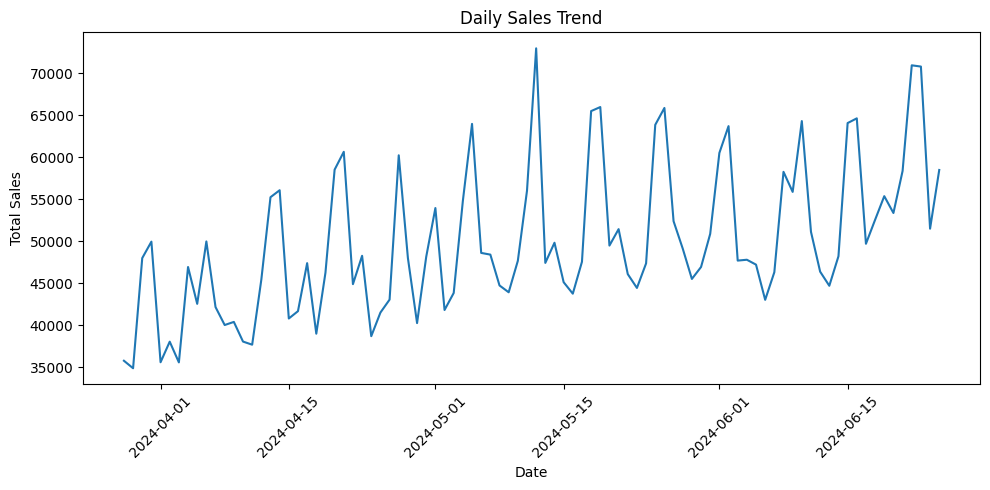

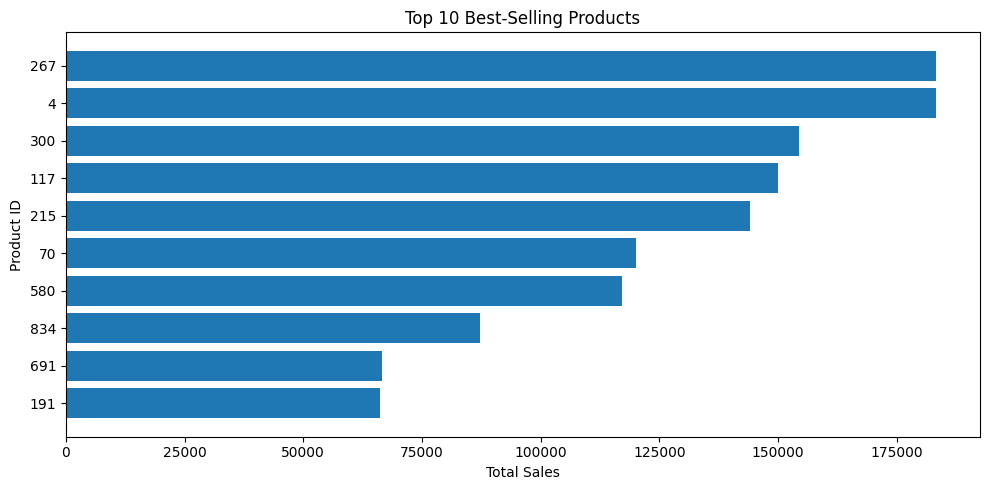

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

# Chart 1: Daily Sales Trend
daily_sales = (
    df.groupby("dt")["sale_amount"]
    .sum()
)

plt.figure(figsize=(10, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("daily_sales_trend.png", dpi=300)
plt.show()


# Chart 2: Top 10 Best-Selling Products
top_products = (
    df.groupby("product_id")["sale_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 5))
plt.barh(
    top_products.index.astype(str),
    top_products.values
)
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Sales")
plt.ylabel("Product ID")
plt.tight_layout()
plt.savefig("top_10_products.png", dpi=300)
plt.show()


# Download both charts
from google.colab import files

files.download("daily_sales_trend.png")
files.download("top_10_products.png")